In [1]:
%run ./01_load_and_process.ipynb

2016-06-01T00:00:08.184 2021-02-28T23:59:09.184 2016-06-01T00:05:00.000 2021-02-28T23:55:00.000


Displaying the entire integrate intensity of our subject of interest

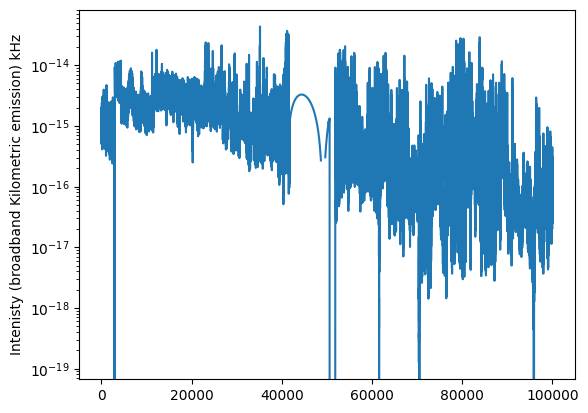

In [9]:
plt.plot(normalized_integrated_intensity_bKOM[0:100000])
plt.ylabel('Intenisty (broadband Kilometric emission) kHz')
plt.yscale('log')
plt.show()

## Interaction of Solar wind and Jovian magnetosphere

(A) Data representation

In [36]:
import numpy as np

# A.0 Analysis interval

start = pd.Timestamp("2016-06-01 00:00:00")
end   = pd.Timestamp("2021-02-27 22:00:00")

In [37]:
# A.1 Build Juno bKOM + distance dataframe
df_juno_min = pd.DataFrame({"time": pd.to_datetime(time_over_year_sec, unit="s"), "intensity_raw": normalized_integrated_intensity_bKOM, "dist_RJ": obdist})
df_juno_min = df_juno_min.set_index("time").sort_index()

# Replace non-physical intensity values with NaN
df_juno_min["intensity"] = df_juno_min["intensity_raw"].where(df_juno_min["intensity_raw"] > 0, np.nan)

# Slice minute-level data
df_juno_min_subset = df_juno_min.loc[start:end].copy()

# A.2 Hourly resampling
df_hourly = pd.DataFrame()

df_hourly["intensity"] = (df_juno_min["intensity"].resample("1H").mean())
df_hourly["dist"] = (df_juno_min["dist_RJ"].resample("1H").mean())
df_hourly1 = df_hourly.loc[start:end].copy()

# A.3 Data-quality checks
raw_subset = df_juno_min.loc[start:end, "intensity_raw"]
n_total = len(raw_subset)
n_zero = (raw_subset == 0).sum()

print("\n--- Juno bKOM quality check ---")
print(f"Total minute samples      : {n_total}")
print(f"Zero samples              : {n_zero}")
print(f"Zero fraction             : {100*n_zero/n_total:.2f}%")



--- Juno bKOM quality check ---
Total minute samples      : 2622120
Zero samples              : 6709
Zero fraction             : 0.26%


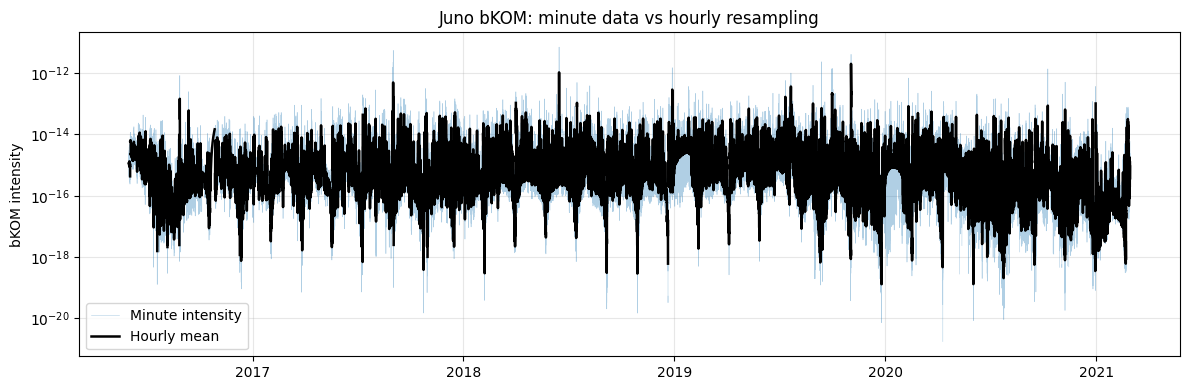

In [8]:
# A.4 Resampling sanity plot
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(df_juno_min_subset.index, df_juno_min_subset["intensity"], lw=0.4, alpha=0.35, label="Minute intensity")
ax.plot(df_hourly1.index, df_hourly1["intensity"], lw=1.8, color="black", label="Hourly mean")

ax.set_yscale("log")
ax.set_ylabel("bKOM intensity")
ax.set_title("Juno bKOM: minute data vs hourly resampling")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [38]:
# A.5 MMESH variables
P_dyn = MMESH_slicing(start, end, "P_dyn")
B_mag = MMESH_slicing(start, end, "B_mag")
u_mag = MMESH_slicing(start, end, "u_mag")
n_tot = MMESH_slicing(start, end, "n_tot")

timestamps = MMESH_slicing(start, end, "1").index

print("\n--- MMESH cadence check ---")
print(P_dyn.index.to_series().diff().value_counts().head())

print("\nMMESH ranges:")
print("P_dyn:", P_dyn.min(), P_dyn.max())
print("B_mag:", B_mag.min(), B_mag.max())
print("u_mag:", u_mag.min(), u_mag.max())
print("n_tot:", n_tot.min(), n_tot.max())

# A.6 Alignment check
df_align_check = pd.concat([df_hourly1["intensity"], P_dyn.rename("P_dyn"), B_mag.rename("B_mag"), u_mag.rename("u_mag"), n_tot.rename("n_tot")], axis=1)

print("\n--- Alignment check ---")
print(df_align_check.shape)


--- MMESH cadence check ---
datetime
0 days 01:00:00    41590
Name: count, dtype: int64

MMESH ranges:
P_dyn: 0.0026 0.9559
B_mag: 0.0271 3.5893
u_mag: 307.7363 590.3313
n_tot: 0.0073 2.9196

--- Alignment check ---
(41591, 5)


(B) JSE angles

In [39]:
# JSE reliability / geometry
JSE_VALID_RANGE = (-180, 180)


# B.1 Load JSE angle file
path_jse = "/obs/kkesri/code/data/output-jup_sw_da_2016.txt"

df_jse = pd.read_csv(path_jse, comment="#", sep=r"\s+",  names=["time", "angle"])
df_jse["time"] = pd.to_datetime(df_jse["time"])
df_jse = df_jse.set_index("time").sort_index()

# B.2 Clean JSE angle
df_jse["angle"] = df_jse["angle"].where(df_jse["angle"].between(*JSE_VALID_RANGE), np.nan)
df_jse["angle"] = df_jse["angle"].interpolate(method="time")

df_jse_subset = df_jse.loc[start:end].copy()

print("\n--- JSE angle check ---")
print(df_jse_subset.head())
print(df_jse_subset.tail())
print(df_jse_subset["angle"].describe())


--- JSE angle check ---
                      angle
time                       
2016-06-01 00:00:00  63.332
2016-06-01 01:00:00  63.389
2016-06-01 02:00:00  63.449
2016-06-01 03:00:00  63.514
2016-06-01 04:00:00  63.583
                         angle
time                          
2021-02-27 18:00:00 -73.141210
2021-02-27 19:00:00 -74.178674
2021-02-27 20:00:00 -75.216138
2021-02-27 21:00:00 -76.253602
2021-02-27 22:00:00 -77.291066
count    41591.000000
mean        14.485550
std        108.245971
min       -179.990000
25%        -80.174500
50%         20.080000
75%        109.945000
max        180.000000
Name: angle, dtype: float64


(C) Identifying the MMESH events

In [40]:
# Parameters
SMOOTH = 3
PLATEAU_FRACTION = 0.9
MIN_EVENT_DURATION = 3

# ID:: 0=P_dyn, 1=B_mag, 2=n_tot, 3=u_mag
ID = 0 
PAR = [P_dyn, B_mag, n_tot, u_mag] # parameters

# User-defined case. 0: default case, i.e., 95 %ile, 1: strict value (mean, median, or any certain value)
CASE = 1

In [ ]:
# Depending on the case value, the code will either take derivatioves or will work with a concrete value
if CASE == 0 :
    PAR_smooth = PAR[ID].rolling(SMOOTH, center=True, min_periods=1).mean()
    dPAR = PAR_smooth.diff()

    positive_dPAR = dPAR[dPAR > 0].dropna()
    PAR_DERIV_THRESHOLD = positive_dPAR.quantile(0.95)

    rising = dPAR > PAR_DERIV_THRESHOLD

elif CASE == 1:
    PAR_smooth = PAR[ID].rolling(SMOOTH, center=True, min_periods=1).mean()
    PAR_DERIV_THRESHOLD = PAR[ID].mean()
    rising = PAR[ID] > PAR_DERIV_THRESHOLD

# Main loop
forcing_records = []
in_forcing = False
forcing_start = None

for t in rising.index:

    if rising.loc[t] and not in_forcing:
        in_forcing = True
        forcing_start = t

    elif (not rising.loc[t]) and in_forcing:

        forcing_rise_end = t

        forcing_rise_duration_hr = (forcing_rise_end - forcing_start).total_seconds() / 3600

        if forcing_rise_duration_hr >= MIN_EVENT_DURATION:

            rise_end_value = PAR_smooth.asof(forcing_rise_end)
            plateau_threshold = PLATEAU_FRACTION * rise_end_value

            after_rise = PAR_smooth.loc[forcing_rise_end:]
            forcing_plateau_end = after_rise.index[-1]

            for tt, val in after_rise.items():
                if val < plateau_threshold:
                    forcing_plateau_end = tt
                    break

            forcing_window = PAR_smooth.loc[forcing_start:forcing_plateau_end]

            forcing_peak_time = forcing_window.idxmax()
            forcing_peak_value = forcing_window.max()
            forcing_midpoint = (forcing_start + (forcing_rise_end - forcing_start) / 2)

            forcing_plateau_duration_hr = (forcing_plateau_end - forcing_rise_end).total_seconds() / 3600
            forcing_duration_hr = (forcing_plateau_end - forcing_start).total_seconds() / 3600

            forcing_records.append({
                "forcing_start": forcing_start,
                "forcing_rise_end": forcing_rise_end,
                "forcing_midpoint": forcing_midpoint,
                "forcing_peak_time": forcing_peak_time,
                "forcing_peak_value": forcing_peak_value,
                "forcing_plateau_end": forcing_plateau_end,
                "forcing_rise_duration_hr": forcing_rise_duration_hr,
                "forcing_plateau_duration_hr": forcing_plateau_duration_hr,
                "forcing_duration_hr": forcing_duration_hr,
            })

        in_forcing = False

df_forcing = pd.DataFrame(forcing_records)

if not df_forcing.empty:
    df_forcing = df_forcing.set_index("forcing_midpoint")

print(df_forcing["forcing_peak_value"])


forcing_midpoint
2016-06-01 09:00:00    0.138267
2016-06-09 11:30:00    0.170100
2016-06-16 12:00:00    0.168433
2016-06-22 18:00:00    0.284633
2016-07-04 03:00:00    0.139200
                         ...   
2021-01-25 09:30:00    0.321567
2021-02-04 18:00:00    0.148167
2021-02-09 15:00:00    0.165567
2021-02-12 05:00:00    0.647933
2021-02-17 19:00:00    0.647933
Name: forcing_peak_value, Length: 190, dtype: float64


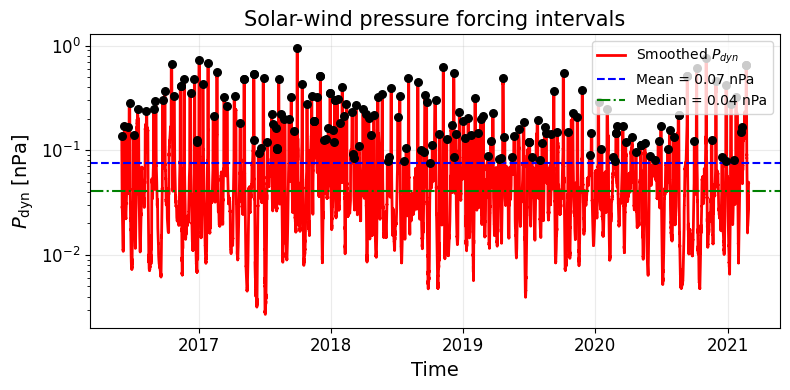

In [35]:
P_mean = P_dyn.mean()
P_median = P_dyn.median()

fig, ax = plt.subplots(figsize=(8, 4), sharex=True)

# ---------------- P_dyn ----------------
#ax[0].plot(P_dyn.index, P_dyn, color="lightcoral", lw=1,
#           label="Raw $P_{dyn}$")
ax.plot(PAR_smooth.index, PAR_smooth, color="red", lw=2,
           label="Smoothed $P_{dyn}$")

for t_mid, row in df_forcing.iterrows():
    ax.scatter(row["forcing_peak_time"], row["forcing_peak_value"],
                  color="black", s=30, zorder=5)

ax.axhline(P_mean, color="blue", ls="--", lw=1.5,
              label=f"Mean = {P_mean:.2f} nPa")
ax.axhline(P_median, color="green", ls="-.", lw=1.5,
              label=f"Median = {P_median:.2f} nPa")

ax.set_yscale("log")
ax.set_ylabel(r"$P_{\rm dyn}$ [nPa]", fontsize=14)
ax.set_xlabel("Time", fontsize=14)
ax.set_title("Solar-wind pressure forcing intervals", fontsize=15)
ax.tick_params(labelsize=12)
ax.legend(fontsize=10)
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


(D) Find bKOM response + gaussian envelope to find the active duration

In [45]:
# bKOM response search
BKOM_SEARCH_WINDOW = 36       # ± hours around P_dyn event midpoint

# Envelope variables
ENVELOPE_WINDOW = 20
ENVELOPE_QUANTILE = 0.90

# Gaussian variables
FIT_WINDOW_BEFORE = 70
FIT_WINDOW_AFTER  = 70
MAX_ACTIVE_DURATION_HR = FIT_WINDOW_BEFORE + FIT_WINDOW_AFTER
MAX_SIGMA_HR = MAX_ACTIVE_DURATION_HR / 4
T0_BOUND = 36   # Gaussian centre allowed within ±36 h of burst peak

MIN_FIT_POINTS = 1

In [66]:
from scipy.optimize import curve_fit
from scipy.signal import find_peaks

# Gaussian model
def gaussian_pulse(t, baseline, amp, t0, sigma_t):
    return baseline + amp * np.exp(-0.5 * ((t - t0) / sigma_t)**2)

# -----------------------------------------------------------------------------
# Main loop
# -----------------------------------------------------------------------------

bkom_results = []
used_response_times = []

for t_forcing, forcing_row in df_forcing.iterrows():

    # =========================================================================
    # LAYER 1: FIND bKOM BURST WITHIN ± BKOM_SEARCH_WINDOW
    # =========================================================================

    response_window = df_hourly.loc[
        t_forcing - pd.Timedelta(hours=BKOM_SEARCH_WINDOW):
        t_forcing + pd.Timedelta(hours=BKOM_SEARCH_WINDOW),
        "intensity"
    ].dropna()

    if len(response_window) < 5:
        continue

    logI_response = np.log10(response_window[response_window > 0]).dropna()

    if len(logI_response) < 5:
        continue

    dlogI = logI_response.diff()
    rising = dlogI > 0

    segments = []
    current_segment = []

    for t in rising.index:

        if rising.loc[t]:
            current_segment.append(t)

        else:
            if len(current_segment) > 1:
                segments.append(current_segment)
            current_segment = []

    if len(current_segment) > 1:
        segments.append(current_segment)

    if len(segments) == 0:
        continue

    # choose strongest log jump
    best_jump = -np.inf
    best_segment = None

    for seg in segments:

        t_start = seg[0]
        t_end   = seg[-1]

        jump = logI_response.loc[t_end] - logI_response.loc[t_start]

        if jump > best_jump:
            best_jump = jump
            best_segment = (t_start, t_end)

    burst_base, burst_peak = best_segment

    baseline_log = logI_response.loc[burst_base]
    peak_log     = logI_response.loc[burst_peak]

    jump_log = peak_log - baseline_log
    response_ratio = 10**jump_log

    burst_midpoint = burst_base + (burst_peak - burst_base) / 2

    burst_duration_hr = (
        burst_peak - burst_base
    ).total_seconds() / 3600

    # avoid assigning same burst to nearby forcing events
    if any(
        abs((burst_midpoint - used).total_seconds() / 3600) < 6
        for used in used_response_times
    ):
        continue

    used_response_times.append(burst_midpoint)

    # Correct lag definitions
    lag_hours_peak = (burst_peak - forcing_row["forcing_rise_end"]).total_seconds() / 3600
    lag_hours_onset = (burst_base - forcing_row["forcing_start"]).total_seconds() / 3600
    lag_hours_midpoints = (burst_midpoint - t_forcing).total_seconds() / 3600

    # =========================================================================
    # LAYER 2: GAUSSIAN FIT TO ROLLING UPPER ENVELOPE
    # =========================================================================

    fit_window = df_hourly.loc[
        burst_peak - pd.Timedelta(hours=FIT_WINDOW_BEFORE):
        burst_peak + pd.Timedelta(hours=FIT_WINDOW_AFTER),
        "intensity"
    ].dropna()

    logI_fit = np.log10(fit_window[fit_window > 0]).dropna()

    if len(logI_fit) < MIN_FIT_POINTS:

        fit_success = False

        active_start = burst_base
        active_end = burst_peak
        active_duration_hr = burst_duration_hr

        fit_baseline = np.nan
        fit_amp = np.nan
        fit_t0 = np.nan
        fit_sigma_hr = np.nan
        energy_proxy = np.nan

    else:
        # Defining the envelope, about two jovian rotations
        envelope = (logI_fit.rolling(ENVELOPE_WINDOW, center=True, min_periods=1).quantile(ENVELOPE_QUANTILE))
        t_hours = (envelope.index - burst_peak).total_seconds() / 3600
        y = envelope.values

        baseline_guess = np.nanpercentile(y, 20)
        amp_guess = np.nanmax(y) - baseline_guess

        if amp_guess <= 0:
            amp_guess = 0.1

        t0_guess = t_hours[np.nanargmax(y)]
        t0_guess = np.clip(t0_guess, -T0_BOUND + 0.01, T0_BOUND - 0.01)

        sigma_guess = 18.0
 
        p0 = [baseline_guess, amp_guess, t0_guess, sigma_guess]

        bounds = ([np.nanmin(y) - 1.0, 0.0, -T0_BOUND, 2.0],[np.nanmax(y) + 1.0, 5.0, T0_BOUND, MAX_SIGMA_HR])

        try:
            popt, pcov = curve_fit(gaussian_pulse, t_hours, y, p0=p0, bounds=bounds, maxfev=20000)
            fit_baseline, fit_amp, fit_t0, fit_sigma_hr = popt

            # Main active-duration definition: ±2 sigma
            active_start = burst_peak + pd.Timedelta(hours=fit_t0 - 2 * fit_sigma_hr)
            active_end = burst_peak + pd.Timedelta(hours=fit_t0 + 2 * fit_sigma_hr)

            active_duration_hr = 4 * fit_sigma_hr

            # Integral of Gaussian excess above baseline in log-space units
            response_area_log = 0.95 * fit_amp * fit_sigma_hr * np.sqrt(2 * np.pi)

            fit_success = True

            # Goodness of fit statistic, R^2 statistics.
            y_fit = gaussian_pulse(t_hours, *popt)
            ss_res = np.sum((y - y_fit)**2)
            ss_tot = np.sum((y - np.mean(y))**2)
            fit_r2 = 1 - ss_res / ss_tot

        except Exception:

            fit_success = False

            active_start = burst_base
            active_end = burst_peak
            active_duration_hr = burst_duration_hr

            fit_baseline = np.nan
            fit_amp = np.nan
            fit_t0 = np.nan
            fit_sigma_hr = np.nan
            response_area_log = np.nan

        # =========================================================================
        # PEAKS ABOVE GAUSSIAN HALF-MAXIMUM
        # =========================================================================

        active_logI = (np.log10(df_hourly.loc[active_start:active_end, "intensity"]).replace([np.inf, -np.inf], np.nan).dropna())

        if fit_success and len(active_logI) >= 3:
            # Half-maximum of fitted Gaussian ABOVE the fitted baseline
            half_max_level = fit_baseline + 0.5 * fit_amp
            fwhm_hr = (2 * np.sqrt(2 * np.log(2)) * fit_sigma_hr)

            # Find all local maxima
            peaks, _ = find_peaks(active_logI.values)

            # Keep only peaks above Gaussian half-maximum
            major_peaks = peaks[active_logI.values[peaks] >= half_max_level]

            n_peaks = len(major_peaks) # number of peaks within the gaussian fit

        else:

            half_max_level = np.nan
            n_peaks = np.nan

    # =========================================================================
    # Juno distance during active interval
    # =========================================================================

    dist_window = df_hourly.loc[active_start:active_end, "dist"].dropna()

    if len(dist_window) > 0:
        r_min_RJ = dist_window.min()
        r_max_RJ = dist_window.max()
        r_mean_RJ = dist_window.mean()
        r_std_RJ = dist_window.std()
    else:
        r_min_RJ = np.nan
        r_max_RJ = np.nan
        r_mean_RJ = np.nan
        r_std_RJ = np.nan

    # =========================================================================
    # STORE
    # =========================================================================

    bkom_results.append({
        "forcing_midpoint": t_forcing,

        # burst quantities
        "burst_base": burst_base,
        "burst_peak": burst_peak,
        "burst_midpoint": burst_midpoint,
        "burst_duration_hr": burst_duration_hr,

        # lag quantities
        "lag_hours_peak": lag_hours_peak,
        "lag_hours_onset": lag_hours_onset,
        "lag_hours_midpoints": lag_hours_midpoints,

        # response strength
        "baseline_log": baseline_log,
        "peak_log": peak_log,
        "jump_log": jump_log,
        "response_ratio": response_ratio,

        # active interval: ±2 sigma
        "active_start": active_start,
        "active_end": active_end,
        "active_duration_hr": active_duration_hr,

        # Gaussian fit
        "fit_success": fit_success,
        "fit_baseline_log": fit_baseline,
        "fit_amp_log": fit_amp,
        "fit_t0_hr": fit_t0,
        "fit_sigma_hr": fit_sigma_hr,
        "response_area_log": response_area_log,
        "fit_r2" : fit_r2,
        "fwhm_hr" : fwhm_hr,
        "half_max_log" : half_max_level,

        # Juno distance
        "r_min_RJ": r_min_RJ,
        "r_max_RJ": r_max_RJ,
        "r_mean_RJ": r_mean_RJ,
        "r_std_RJ": r_std_RJ,
        "n_peaks" : n_peaks,
    })


df_bkom = pd.DataFrame(bkom_results)

if not df_bkom.empty:
    df_bkom = df_bkom.set_index("forcing_midpoint")

#print(df_bkom)

In [50]:
# =============================================================================
# PART E — JOIN FORCING + BKOM RESPONSE
# =============================================================================

df_combined = df_forcing.join(df_bkom, how="inner")

(F) JSO LOCAL TIME + SECTOR CLASSIFICATION

In [ ]:
file_jso = '/obs/kkesri/code/ephem/juno_jup_xyz_jso_2016_2025.txt'

df_jso = pd.read_csv(
    file_jso,
    comment="#",
    sep=r"\s+",
    names=["time", "x_jso", "y_jso", "z_jso"]
)

df_jso["time"] = pd.to_datetime(df_jso["time"])
df_jso = df_jso.set_index("time").sort_index()

In [ ]:
import numpy as np
# Longitude in degrees from JSO X-Y plane
df_jso["longitude_deg"] = np.degrees(np.arctan2(df_jso["y_jso"], df_jso["x_jso"]))

# Convert longitude to local time
# x > 0 = Sunward = 12 LT
# x < 0 = anti-Sunward = 00 LT
df_jso["local_time_hr"] = np.mod(12 + (df_jso["longitude_deg"] / 180.0) * 12, 24)

# Sector classification:
# midnight: 21–03
# dawn:      03–09
# noon:      09–15
# dusk:      15–21

def classify_lt_sector(lt):
    if (lt >= 21) or (lt < 3):
        return "midnight"
    elif 3 <= lt < 9:
        return "dawn"
    elif 9 <= lt < 15:
        return "noon"
    elif 15 <= lt < 21:
        return "dusk"
    else:
        return np.nan

df_jso["lt_sector"] = df_jso["local_time_hr"].apply(classify_lt_sector)

In [ ]:
df_combined["x_jso"] = df_jso["x_jso"].reindex(df_combined.index, method="nearest")
df_combined["y_jso"] = df_jso["y_jso"].reindex(df_combined.index, method="nearest")
df_combined["z_jso"] = df_jso["z_jso"].reindex(df_combined.index, method="nearest")
df_combined["local_time_hr"] = df_jso["local_time_hr"].reindex(df_combined.index, method="nearest")
df_combined["lt_sector"] = df_jso["lt_sector"].reindex(df_combined.index, method="nearest")

In [ ]:
print(df_combined)